# 60 · 33 with zoom on half the images and 64 px shifts

- Change from 33: zoom 0.8–1.2 on half the images, and RandAugment runs on a 24 px reflect-padded image with shifts sized for 64 px (4 px instead of 8). The ±4 px whole-pixel shift is kept.
- Compare with 33 (63.88), 39 (64.07) and 41 on mean val of epochs 96–100. After training: object-size and blur tables.

In [1]:
import os
import random
from pathlib import Path
import numpy as np
import pandas as pd
import torch

# torch.set_num_threads(8)
# print("PyTorch CPU threads:", torch.get_num_threads())

from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

from src.dataset.balanced_class_subset import BalancedClassSubset
from src.dataset.tiny_imagenet_dataset import TinyImageNetLoader, get_tiny_imagenet_class_names
from archive.utils import means, stds, convert_to_rgb, get_device, print_device_info
from src.dataset.noise_and_augumentation import MixUpAugumentation, CutMixAugumentation
from archive.dataset.randaugment_fixed import RandAugment64

RESUME = False
SEED = 42
NUM_CLASSES = 200
TRAIN_PER_CLASS = 500
VAL_PER_CLASS = 50
BATCH_SIZE = 64
NUM_WORKERS = 4
EPOCHS = 100
INITIAL_LR = 0.05
MIN_LR = 1e-05
WEIGHT_DECAY = 0.0001
LABEL_SMOOTHING = 0.1
CLASSIFIER_DROPOUT = 0.35
CLEAN_EVAL_INTERVAL = 5

MIXUP_ALPHA = 0.2
CUTMIX_ALPHA = 1.0
CLEAN_PROB = 0.50
MIXUP_PROB = 0.25
CUTMIX_PROB = 0.25

assert abs(CLEAN_PROB + MIXUP_PROB + CUTMIX_PROB - 1.0) < 1e-12

SAVE_DIR = Path('checkpoints_60_zoom')
SAVE_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = get_device()

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print('Device:', DEVICE)
print('DataLoader workers:', NUM_WORKERS)
print('Epochs:', EPOCHS)
print(f'Batch probabilities: Clean={CLEAN_PROB:.0%} | MixUp={MIXUP_PROB:.0%} | CutMix={CUTMIX_PROB:.0%}')
print(f'MixUp alpha={MIXUP_ALPHA} | CutMix alpha={CUTMIX_ALPHA}')

Device: mps
DataLoader workers: 4
Epochs: 100
Batch probabilities: Clean=50% | MixUp=25% | CutMix=25%
MixUp alpha=0.2 | CutMix alpha=1.0


In [2]:
print_device_info(DEVICE)

Number of MPS devices: 1


## 1. Local model and reference dataset loader

In [3]:
TINY_ROOT = Path('../data/tiny_imagenet/tiny-imagenet-200')
SELECTED_CLASSES = list(range(NUM_CLASSES))
print('Dataset root:', TINY_ROOT)

Dataset root: ../data/tiny_imagenet/tiny-imagenet-200


In [4]:
FILL = tuple(int(m * 255) for m in means)

train_tf = transforms.Compose(
    [transforms.Lambda(convert_to_rgb),
     transforms.Pad(24, padding_mode='reflect'),
     RandAugment64(num_ops=2, magnitude=5, interpolation=InterpolationMode.BILINEAR, fill=FILL),
     transforms.RandomApply([transforms.RandomAffine(degrees=0, scale=(0.8, 1.2), interpolation=InterpolationMode.BILINEAR)], p=0.5),
     transforms.RandomAffine(degrees=0, translate=(0.036, 0.036)),
     transforms.CenterCrop(64),
     transforms.RandomHorizontalFlip(p=0.5),
     transforms.ToTensor(),
     transforms.Normalize(mean=means, std=stds)])
test_tf = transforms.Compose(
    [transforms.Lambda(convert_to_rgb), transforms.ToTensor(), transforms.Normalize(mean=means, std=stds)])

train_dataset, val_dataset, _, _ = TinyImageNetLoader(seed=SEED, root=TINY_ROOT, train_transform=train_tf,
                                                      test_transform=test_tf).load()
clean_train_dataset, _, _, _ = TinyImageNetLoader(seed=SEED, root=TINY_ROOT, train_transform=test_tf,
                                                  test_transform=test_tf).load()

if not hasattr(clean_train_dataset, 'transform'):
    raise AttributeError('Expected the dataset to expose a transform attribute.')

train_subset = BalancedClassSubset(train_dataset, SELECTED_CLASSES, TRAIN_PER_CLASS, seed=SEED)
clean_train_subset = BalancedClassSubset(clean_train_dataset, SELECTED_CLASSES, TRAIN_PER_CLASS, seed=SEED)
val_subset = BalancedClassSubset(val_dataset, SELECTED_CLASSES, VAL_PER_CLASS, seed=SEED + 1)

assert train_subset.samples == clean_train_subset.samples, 'Clean and augmented training subsets differ.'
assert len(train_subset) == NUM_CLASSES * TRAIN_PER_CLASS
assert len(val_subset) == NUM_CLASSES * VAL_PER_CLASS

FULL_CLASS_NAMES = get_tiny_imagenet_class_names(train_dataset, TINY_ROOT)
CLASS_NAMES = [FULL_CLASS_NAMES[i] for i in SELECTED_CLASSES]

print('Train:', len(train_subset), 'Validation:', len(val_subset))

Train: 100000 Validation: 10000


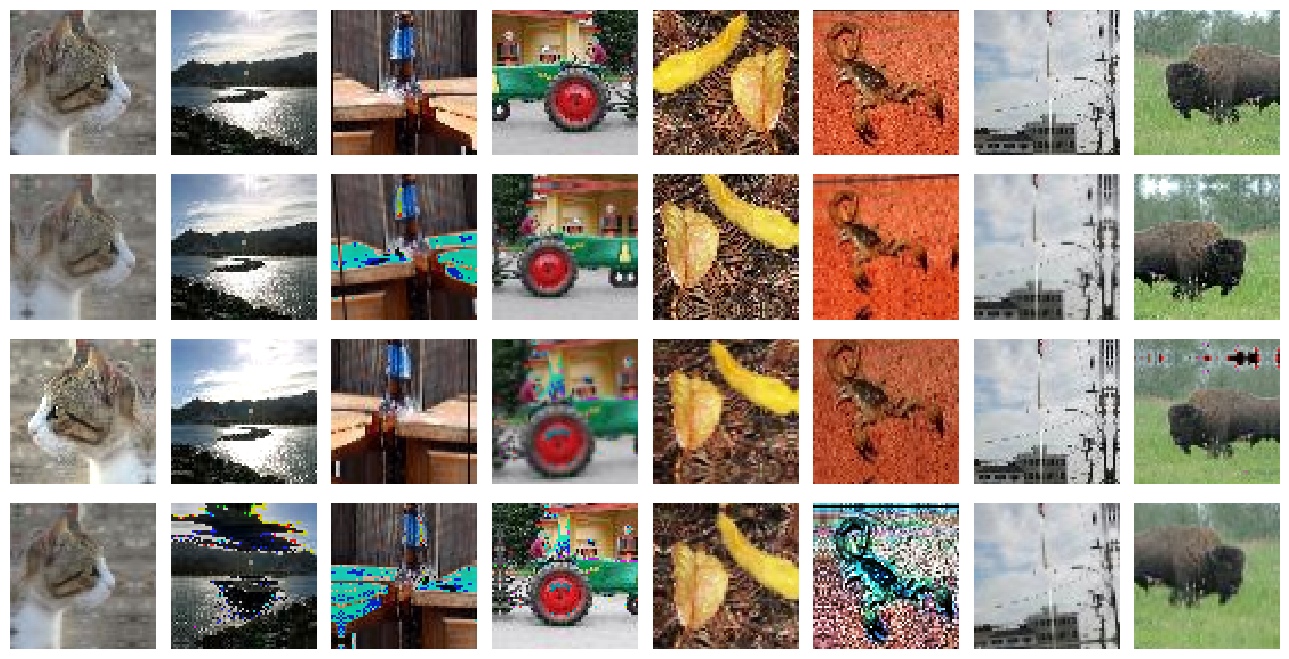

In [5]:
# Sample check: look at these before training. Top row plain, other rows augmented.
_samples = [train_dataset.samples[i][0] for i in range(0, len(train_dataset), len(train_dataset) // 8)][:8]
from PIL import Image as _Image
_fig, _axs = plt.subplots(4, 8, figsize=(13, 6.8))
_to_rgb = lambda t: (t * torch.tensor(stds).view(3, 1, 1) + torch.tensor(means).view(3, 1, 1)).clamp(0, 1).permute(1, 2, 0).numpy()
for _c, _p in enumerate(_samples):
    _im = _Image.open(_p).convert('RGB')
    _axs[0, _c].imshow(_im, interpolation='nearest')
    for _r in range(1, 4):
        _axs[_r, _c].imshow(_to_rgb(train_tf(_im)), interpolation='nearest')
for _ax in _axs.flat: _ax.axis('off')
plt.tight_layout()
plt.show()

## 2. DataLoaders (macOS / Jupyter safe)

In [6]:
loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

loader_options = {'batch_size': BATCH_SIZE, 'num_workers': NUM_WORKERS, 'pin_memory': DEVICE.type == 'cuda',
                  'persistent_workers': NUM_WORKERS > 0, **({'prefetch_factor': 2} if NUM_WORKERS > 0 else {})}

train_loader = DataLoader(train_subset, shuffle=True, generator=loader_generator, **loader_options)
val_loader = DataLoader(val_subset, shuffle=False, **loader_options)
clean_train_loader = DataLoader(clean_train_subset, shuffle=False, **loader_options)

print('Training batches:', len(train_loader))
print('Validation batches:', len(val_loader))

Training batches: 1563
Validation batches: 157


## Visual Check

In [7]:
# NUM_SHOW = 5
#
# train_iter = iter(train_loader)
# clean_train_iter = iter(clean_train_loader)
# val_iter = iter(val_loader)

In [8]:
# train_images, train_labels = next(train_iter)
# clean_train_images, clean_train_labels = next(clean_train_iter)
# val_images, val_labels_batch = next(val_iter)
#
# show_image(train_images, train_labels, NUM_SHOW, CLASS_NAMES, name="Train Images", has_norm=True)
# show_image(clean_train_images, clean_train_labels, NUM_SHOW, CLASS_NAMES, name="Clean Train Images", has_norm=True)
# show_image(val_images, val_labels_batch, NUM_SHOW, CLASS_NAMES, name="Validation Images", has_norm=True)

In [9]:
# mixup_images, mixup_labels_a, mixup_labels_b, mixup_lam, _ = MixUpAugumentation(train_images.clone(), train_labels.clone(), alpha=MIXUP_ALPHA)()
# cutmix_images, cutmix_labels_a, cutmix_labels_b, cutmix_lam, _ = CutMixAugumentation(train_images.clone(), train_labels.clone(), alpha=CUTMIX_ALPHA)()
#
# show_mixed_images(mixup_images, mixup_labels_a, mixup_labels_b, mixup_lam, CLASS_NAMES, NUM_SHOW, name="MixUp Images", has_norm=True)
# show_mixed_images(cutmix_images, cutmix_labels_a, cutmix_labels_b, cutmix_lam, CLASS_NAMES, NUM_SHOW, name="CutMix Images", has_norm=True)

## 3. Model, optimizer and cosine scheduler

In [10]:
import torch
import torch.nn as nn


class Our08CNNPoolBN_V2(nn.Module):
    """8Conv (2+2+2+2) | BN + LeakyReLU | MaxPool x3 | GAP | Dense 512→512→200."""

    @staticmethod
    def block(channels, pool_after=False, dilations=(1, 1), dropout=0.0):
        layers = []
        assert len(dilations) == len(channels) - 1

        for i, d in enumerate(dilations):
            layers.extend([
                nn.Conv2d(channels[i], channels[i + 1], kernel_size=3, padding=d, dilation=d, bias=False),
                nn.BatchNorm2d(channels[i + 1]),
                nn.LeakyReLU(0.05, inplace=True)
            ])

        if pool_after: layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
        if dropout > 0: layers.append(nn.Dropout2d(p=dropout))
        return nn.Sequential(*layers)

    def __init__(self, num_classes=200, block3_dropout=0.10, block4_dropout=0.15, classifier_dropout=0.25,
                 level4_dilation=1):
        super().__init__()

        # 64 → 32 → 16 → 8 → 8
        self.level1 = self.block([3, 32, 64], pool_after=True, dilations=(1, 1))
        self.level2 = self.block([64, 64, 128], pool_after=True, dilations=(1, 1))
        self.level3 = self.block([128, 128, 256], pool_after=True, dilations=(1, 1), dropout=block3_dropout)
        self.level4 = self.block([256, 256, 512], pool_after=False, dilations=(1, level4_dilation),
                                 dropout=block4_dropout)

        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.flatten = nn.Flatten()

        # GAP 512 → 512
        self.dense_transition = nn.Sequential(
            nn.Linear(512, 512, bias=False),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.05, inplace=True),
            nn.Dropout(p=classifier_dropout)
        )
        self.classifier = nn.Linear(512, num_classes)

        # Weight initialization
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, a=0.05, mode="fan_out", nonlinearity="leaky_relu")
            elif isinstance(m, (nn.BatchNorm2d, nn.BatchNorm1d)):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

        nn.init.kaiming_normal_(self.dense_transition[0].weight, a=0.05, mode="fan_in", nonlinearity="leaky_relu")
        nn.init.normal_(self.classifier.weight, mean=0.0, std=0.01)
        nn.init.zeros_(self.classifier.bias)

    def forward(self, x, return_features=False):
        x = self.level1(x)
        x = self.level2(x)
        x = self.level3(x)
        x = self.level4(x)

        features = self.flatten(self.avgpool(x))
        embedding = self.dense_transition(features)
        logits = self.classifier(embedding)

        return (logits, embedding) if return_features else logits


# ==========================================
# MODEL INITIALIZATION
# ==========================================

base_model = Our08CNNPoolBN_V2(num_classes=NUM_CLASSES, block3_dropout=0.15, block4_dropout=0.25,
                               classifier_dropout=0.35, level4_dilation=2)

total_params = sum(p.numel() for p in base_model.parameters())
print(f"Parameters: {total_params:,} ({total_params / 1e6:.3f}M)")
print("Architecture: 8Conv (2+2+2+2) | MaxPool x3 | BatchNorm x8 | LeakyReLU 0.05 | GAP → 512 → 512 → 200")

model = base_model.to(DEVICE)


def raw_model(): return model


# LOSS, OPTIMIZER & SCHEDULER
criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
optimizer = torch.optim.SGD(model.parameters(), lr=INITIAL_LR, momentum=0.9, weight_decay=WEIGHT_DECAY, nesterov=True)

TOTAL_STEPS = EPOCHS * len(train_loader)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=TOTAL_STEPS, eta_min=MIN_LR)

# SANITY CHECK
model.eval()
with torch.no_grad():
    dummy = torch.randn(2, 3, 64, 64, device=DEVICE)
    logits, features = model(dummy, return_features=True)

print("Logits shape:", logits.shape)
print("Feature shape:", features.shape)
model.train()

Parameters: 2,710,376 (2.710M)
Architecture: 8Conv (2+2+2+2) | MaxPool x3 | BatchNorm x8 | LeakyReLU 0.05 | GAP → 512 → 512 → 200
Logits shape: torch.Size([2, 200])
Feature shape: torch.Size([2, 512])


Our08CNNPoolBN_V2(
  (level1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.05, inplace=True)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): LeakyReLU(negative_slope=0.05, inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (level2): Sequential(
    (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.05, inplace=True)
    (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(128, eps=1e-05

## 4. Best and latest checkpoints

In [11]:
BEST_PATH = SAVE_DIR / 'best_model.pth'
LATEST_PATH = SAVE_DIR / 'latest_checkpoint.pth'

history = {k: [] for k in
           ['epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'clean_train_loss', 'clean_train_acc', 'lr',
            'generalization_gap']}

best_acc = -1.0
best_epoch = 0
start_epoch = 1


def rng_state():
    return dict(python=random.getstate(), numpy=np.random.get_state(), torch=torch.get_rng_state(),
                cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
                loader=loader_generator.get_state())


def restore_rng(s):
    random.setstate(s['python'])
    np.random.set_state(s['numpy'])
    torch.set_rng_state(s['torch'])
    if torch.cuda.is_available() and s.get('cuda') is not None:
        torch.cuda.set_rng_state_all(s['cuda'])
    loader_generator.set_state(s['loader'])


def save_latest(epoch):
    payload = dict(epoch=epoch, model=raw_model().state_dict(), optimizer=optimizer.state_dict(),
                   scheduler=scheduler.state_dict(), history=history, best_acc=best_acc, best_epoch=best_epoch,
                   rng=rng_state(), config=dict(num_classes=NUM_CLASSES, batch_size=BATCH_SIZE, epochs=EPOCHS,
                                                train_per_class=TRAIN_PER_CLASS, val_per_class=VAL_PER_CLASS,
                                                classifier='8conv_v2_gap_dense_fc',
                                                classifier_dropout=CLASSIFIER_DROPOUT,
                                                augmentation='randaugment64_2m5_zoom08_12half_shift4_50clean_25mixup_25cutmix',
                                                mixup_alpha=MIXUP_ALPHA, cutmix_alpha=CUTMIX_ALPHA,
                                                clean_prob=CLEAN_PROB, mixup_prob=MIXUP_PROB, cutmix_prob=CUTMIX_PROB))
    temp = LATEST_PATH.with_suffix('.tmp')
    torch.save(payload, temp)
    os.replace(temp, LATEST_PATH)


if RESUME:
    ck = torch.load(LATEST_PATH, map_location='cpu', weights_only=False)
    cfg = ck['config']

    if cfg['batch_size'] != BATCH_SIZE or cfg['epochs'] != EPOCHS or cfg.get(
            'classifier') != '8conv_v2_gap_dense_fc' or cfg.get(
            'classifier_dropout') != CLASSIFIER_DROPOUT or cfg.get(
            'augmentation') != 'randaugment64_2m5_zoom08_12half_shift4_50clean_25mixup_25cutmix' or cfg.get(
            'mixup_alpha') != MIXUP_ALPHA or cfg.get('cutmix_alpha') != CUTMIX_ALPHA or cfg.get(
            'clean_prob') != CLEAN_PROB or cfg.get('mixup_prob') != MIXUP_PROB or cfg.get('cutmix_prob') != CUTMIX_PROB:
        raise ValueError(
            'Resume configuration does not match this GAP + 50% Clean + 25% MixUp + 25% CutMix experiment.')

    raw_model().load_state_dict(ck['model'])
    optimizer.load_state_dict(ck['optimizer'])
    scheduler.load_state_dict(ck['scheduler'])

    for state in optimizer.state.values():
        for k, v in state.items():
            if torch.is_tensor(v):
                state[k] = v.to(DEVICE)

    history = ck['history']
    best_acc = ck['best_acc']
    best_epoch = ck['best_epoch']
    start_epoch = ck['epoch'] + 1
    restore_rng(ck['rng'])

    print(f'Resuming from epoch {start_epoch} | LR = {scheduler.get_last_lr()[0]:.10f}')
else:
    print('Starting fresh 8Conv V2 + GAP + Dense + 50% Clean + 25% MixUp + 25% CutMix training from epoch 1.')

Starting fresh 8Conv V2 + GAP + Dense + 50% Clean + 25% MixUp + 25% CutMix training from epoch 1.


## 5. Training and validation

In [12]:
def choose_batch_augmentation(images, labels):
    r = np.random.random()
    if r < CLEAN_PROB:
        return images, labels, labels, 1.0, 'Clean'
    if r < CLEAN_PROB + MIXUP_PROB:
        return MixUpAugumentation(images, labels, alpha=MIXUP_ALPHA)()
    return CutMixAugumentation(images, labels, alpha=CUTMIX_ALPHA)()


def run_epoch(loader, training=False):
    if training:
        model.train()
    else:
        model.eval()

    total_loss = torch.zeros((), device=DEVICE)
    total_correct = torch.zeros((), device=DEVICE)
    total = 0
    clean_batches = 0
    mixup_batches = 0
    cutmix_batches = 0
    context = torch.enable_grad() if training else torch.inference_mode()

    with context:
        for images, labels in tqdm(loader, leave=False, desc='Train' if training else 'Eval'):
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)
                model_images, labels_a, labels_b, lam, batch_type = choose_batch_augmentation(images, labels)

                if batch_type == 'Clean':
                    clean_batches += 1
                elif batch_type == 'MixUp':
                    mixup_batches += 1
                else:
                    cutmix_batches += 1

                logits = model(model_images)

                if batch_type == 'Clean':
                    loss = criterion(logits, labels)
                    correct = (logits.detach().argmax(dim=1) == labels).sum()
                else:
                    loss = lam * criterion(logits, labels_a) + (1.0 - lam) * criterion(logits, labels_b)
                    predictions = logits.detach().argmax(dim=1)
                    correct = lam * (predictions == labels_a).sum() + (1.0 - lam) * (predictions == labels_b).sum()

                loss.backward()
                for p in model.parameters():  # per-tensor clip at 1.0: no BatchNorm, so guard against rare gradient spikes
                    torch.nn.utils.clip_grad_norm_(p, 1.0)
                optimizer.step()
                scheduler.step()
            else:
                logits = model(images)
                loss = criterion(logits, labels)
                correct = (logits.detach().argmax(dim=1) == labels).sum()

            batch_size = labels.size(0)
            total += batch_size
            total_loss += loss.detach() * batch_size
            total_correct += correct

    avg_loss = (total_loss / total).item()
    accuracy = (total_correct * (100.0 / total)).item()

    if training:
        print(f'Batch selection: Clean={clean_batches}, MixUp={mixup_batches}, CutMix={cutmix_batches}')

    return avg_loss, accuracy

In [13]:
for epoch in tqdm(range(start_epoch, EPOCHS + 1)):
    train_loss, train_acc = run_epoch(train_loader, training=True)

    if epoch == 1 or epoch % CLEAN_EVAL_INTERVAL == 0:
        clean_train_loss, clean_train_acc = run_epoch(clean_train_loader, training=False)
    else:
        clean_train_loss, clean_train_acc = None, None

    val_loss, val_acc = run_epoch(val_loader, training=False)
    current_lr = optimizer.param_groups[0]['lr']

    epoch_metrics = {'epoch': epoch, 'train_loss': train_loss, 'train_acc': train_acc, 'val_loss': val_loss,
                     'val_acc': val_acc, 'clean_train_loss': clean_train_loss, 'clean_train_acc': clean_train_acc,
                     'lr': current_lr,
                     'generalization_gap': clean_train_acc - val_acc if clean_train_acc is not None else None}

    for name, value in epoch_metrics.items():
        history[name].append(value)

    if val_acc > best_acc:
        best_acc = val_acc
        best_epoch = epoch
        torch.save({'model': raw_model().state_dict(), 'epoch': epoch, 'val_acc': val_acc, 'class_names': CLASS_NAMES,
                    'experiment': 'Our 08 V2: max-pool after levels 1, 2, 3, Dropout2d, BatchNorm, GAP + dense 512 head, archive flow, 50% Clean + 25% MixUp + 25% CutMix'},
                   BEST_PATH)

    save_latest(epoch)

    clean_text = f'{clean_train_acc:.2f}% / {clean_train_loss:.4f}' if clean_train_acc is not None else 'Skipped'
    print(
        f'Epoch {epoch:03d}/{EPOCHS} | Train: {train_acc:.2f}% / {train_loss:.4f} | Val: {val_acc:.2f}% / {val_loss:.4f} | Clean Train: {clean_text} | LR: {current_lr:.7f} | Best: {best_acc:.2f}% (epoch {best_epoch})')

print(f'Training finished at epoch {EPOCHS}. Best validation accuracy: {best_acc:.2f}% (epoch {best_epoch})')

  0%|          | 0/100 [00:00<?, ?it/s]

Train:   0%|          | 0/1563 [00:06<?, ?it/s]

Batch selection: Clean=775, MixUp=412, CutMix=376


Eval:   0%|          | 0/1563 [00:07<?, ?it/s]

Eval:   0%|          | 0/157 [00:05<?, ?it/s]

Epoch 001/100 | Train: 5.45% / 4.8316 | Val: 10.05% / 4.4093 | Clean Train: 10.25% / 4.4084 | LR: 0.0499877 | Best: 10.05% (epoch 1)


... (412 outputs left out)

Batch selection: Clean=806, MixUp=401, CutMix=356


Eval:   0%|          | 0/1563 [00:00<?, ?it/s]

Eval:   0%|          | 0/157 [00:00<?, ?it/s]

Epoch 100/100 | Train: 58.45% / 2.5516 | Val: 63.36% / 2.1987 | Clean Train: 82.72% / 1.5815 | LR: 0.0000100 | Best: 63.43% (epoch 94)
Training finished at epoch 100. Best validation accuracy: 63.43% (epoch 94)


## 6. Training and validation curves

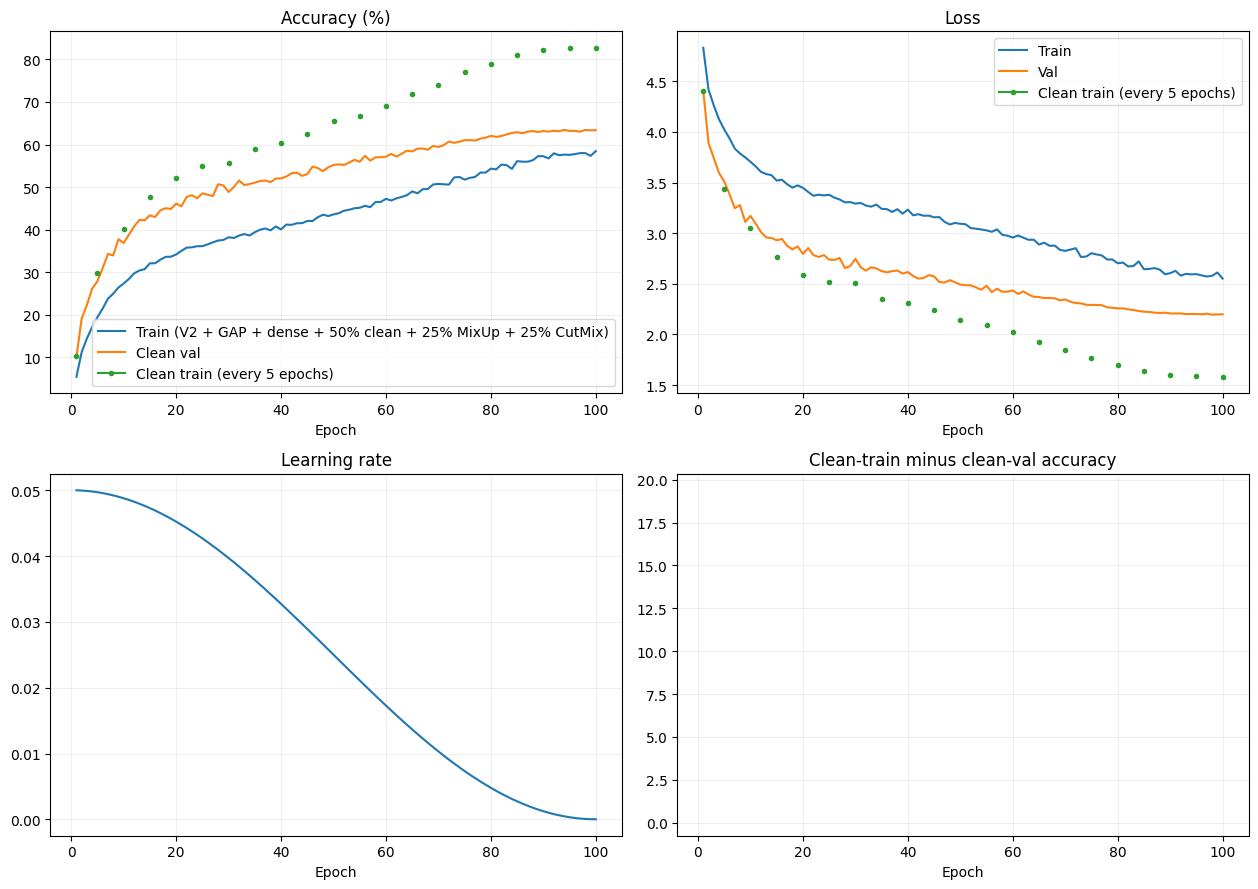

Eval:   0%|          | 0/1563 [00:00<?, ?it/s]

Eval:   0%|          | 0/157 [00:00<?, ?it/s]

Best checkpoint: clean train 82.59%, clean val 63.43%, gap 19.16 pp


In [14]:
h = pd.DataFrame(history)
fig, axs = plt.subplots(2, 2, figsize=(13, 9))

axs[0, 0].plot(h.epoch, h.train_acc, label='Train (V2 + GAP + dense + 50% clean + 25% MixUp + 25% CutMix)')
axs[0, 0].plot(h.epoch, h.val_acc, label='Clean val')
axs[0, 0].plot(h.epoch, h.clean_train_acc, label='Clean train (every 5 epochs)', marker='o', markersize=3)
axs[0, 0].set_title('Accuracy (%)')
axs[0, 0].legend()

axs[0, 1].plot(h.epoch, h.train_loss, label='Train')
axs[0, 1].plot(h.epoch, h.val_loss, label='Val')
axs[0, 1].plot(h.epoch, h.clean_train_loss, label='Clean train (every 5 epochs)', marker='o', markersize=3)
axs[0, 1].set_title('Loss')
axs[0, 1].legend()

axs[1, 0].plot(h.epoch, h.lr)
axs[1, 0].set_title('Learning rate')

axs[1, 1].plot(h.epoch, h.generalization_gap)
axs[1, 1].set_title('Clean-train minus clean-val accuracy')

for ax in axs.flat:
    ax.set_xlabel('Epoch')
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

best = torch.load(BEST_PATH, map_location='cpu', weights_only=False)
raw_model().load_state_dict(best['model'])
model.eval()

clean_train_loss, clean_train_acc = run_epoch(clean_train_loader)
clean_val_loss, clean_val_acc = run_epoch(val_loader)

print(
    f'Best checkpoint: clean train {clean_train_acc:.2f}%, clean val {clean_val_acc:.2f}%, gap {clean_train_acc - clean_val_acc:.2f} pp')

## 7. Object size and position

In [15]:
# Accuracy by object size and position. Val boxes are used for this analysis only, never for training or prediction.
from torchvision.transforms.functional import gaussian_blur

raw_model().eval()
_means = torch.tensor(means, device=DEVICE).view(1, 3, 1, 1)
_stds = torch.tensor(stds, device=DEVICE).view(1, 3, 1, 1)

def val_correct(blur_sigma=None):
    out = []
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            if blur_sigma is not None:
                k = 3 if blur_sigma < 0.8 else 5
                x = (gaussian_blur(x * _stds + _means, [k, k], [blur_sigma, blur_sigma]) - _means) / _stds
            out.append((raw_model()(x).argmax(1) == y).cpu())
    return torch.cat(out).numpy()

_correct = val_correct()
_ann = {}
with open(TINY_ROOT / 'val' / 'val_annotations.txt') as f:
    for line in f:
        p = line.split()
        _ann[p[0]] = tuple(map(int, p[2:6]))
_box = np.array([_ann[val_dataset.samples[i][0].name] for i, _ in val_subset.samples], dtype=float)
_w, _h = _box[:, 2] - _box[:, 0], _box[:, 3] - _box[:, 1]
_area = _w * _h / 4096
_off = np.hypot((_box[:, 0] + _box[:, 2]) / 2 - 32, (_box[:, 1] + _box[:, 3]) / 2 - 32)

print(f'All images: {_correct.mean() * 100:.2f}%')
print('Object fills (33: 46.11, 55.81, 65.99, 70.98, 68.85):')
for lo, hi in [(0, 0.1), (0.1, 0.25), (0.25, 0.5), (0.5, 0.8), (0.8, 1.01)]:
    m = (_area >= lo) & (_area < hi)
    print(f'  {lo * 100:>3.0f}-{min(hi, 1) * 100:>3.0f}%  n={m.sum():>5}  acc={_correct[m].mean() * 100:.2f}%')
print('Distance from centre, nearest to farthest quarter (33: 68.64, 69.80, 64.08, 53.44):')
for part in np.array_split(np.argsort(_off), 4):
    print(f'  {_off[part].min():>4.0f}-{_off[part].max():>4.0f} px  acc={_correct[part].mean() * 100:.2f}%')

All images: 63.43%
Object fills (33: 46.11, 55.81, 65.99, 70.98, 68.85):
    0- 10%  n= 1273  acc=46.74%
   10- 25%  n= 1455  acc=54.91%
   25- 50%  n= 2279  acc=64.33%
   50- 80%  n= 2733  acc=71.68%
   80-100%  n= 2260  acc=67.43%
Distance from centre, nearest to farthest quarter (33: 68.64, 69.80, 64.08, 53.44):
     0-   2 px  acc=67.00%
     2-   6 px  acc=69.92%
     6-  13 px  acc=64.28%
    13-  41 px  acc=52.52%


## 8. Blur sensitivity

In [16]:
# Accuracy with blur added to val images. This measures sensitivity only; blur stays out of training.
print('33: 64.05, 61.62, 54.24, 28.80')
for sigma in [0.3, 0.5, 0.7, 1.0]:
    print(f'  sigma {sigma}: {val_correct(sigma).mean() * 100:.2f}%')

33: 64.05, 61.62, 54.24, 28.80
  sigma 0.3: 63.54%
  sigma 0.5: 63.05%
  sigma 0.7: 61.22%
  sigma 1.0: 49.28%
